# Ray Data: batch inference with an actor pool

map_batches with a callable class and ActorPoolStrategy: each actor runs the expensive setup once and then processes many batches.

**When to use it.** Batch inference or any transform with costly setup, such as loading a model or opening a connection.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

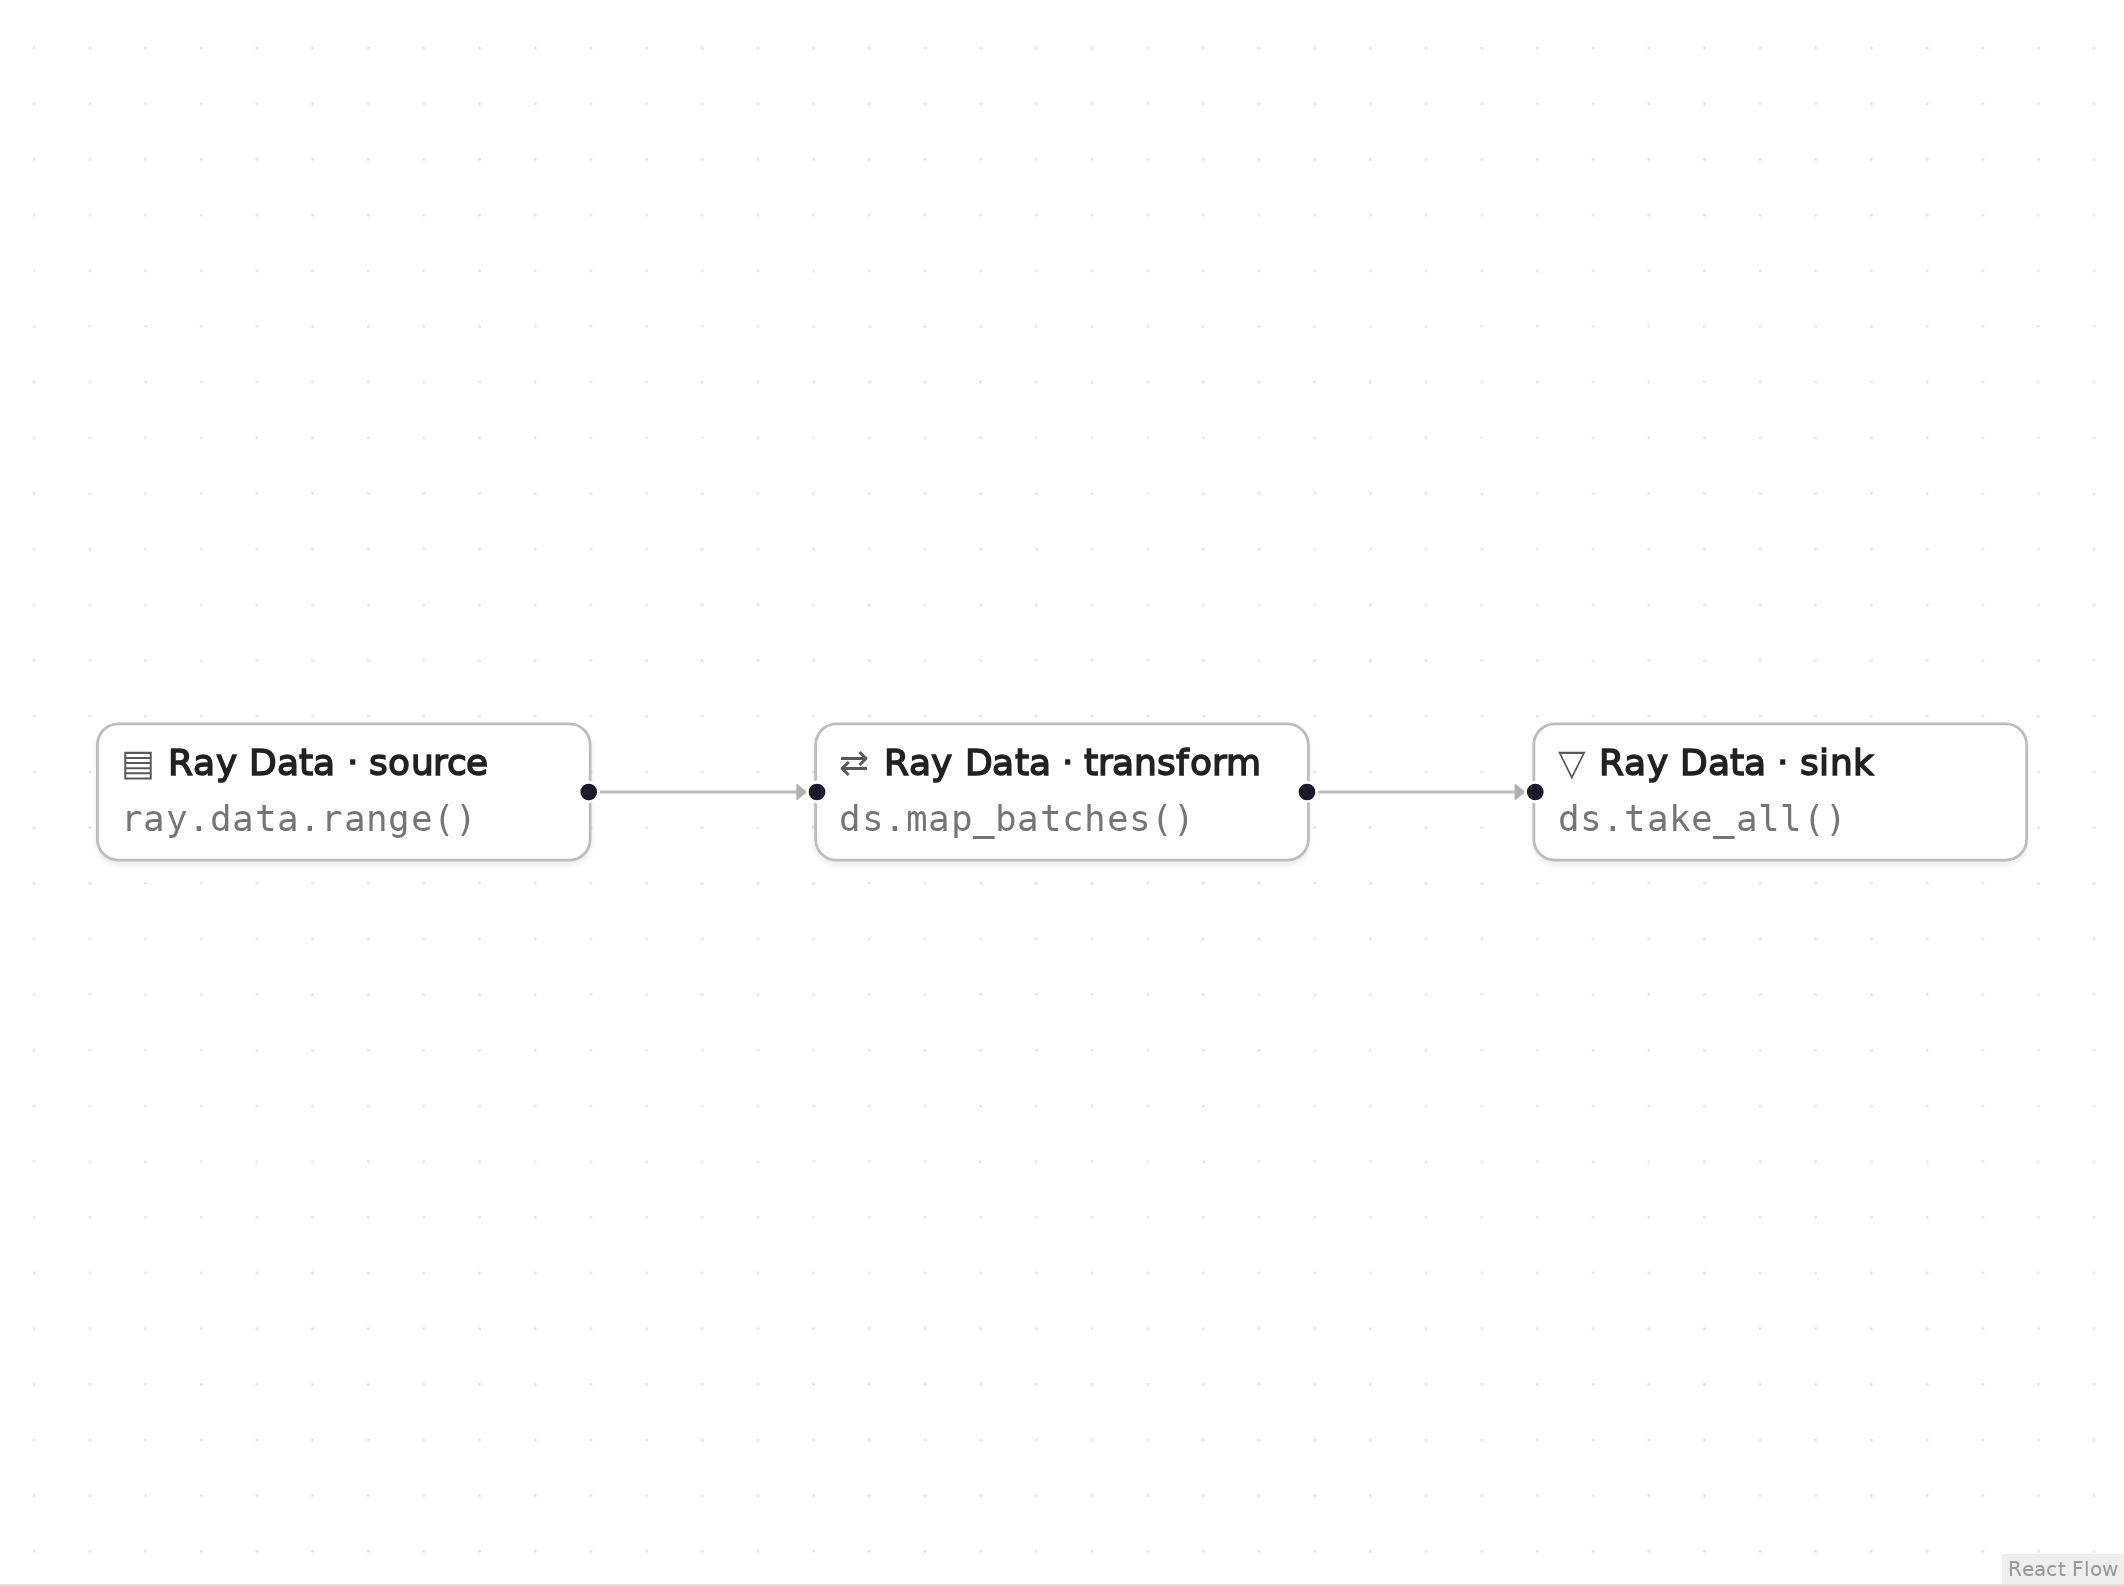

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
class AddOffset:
    def __init__(self, offset):
        # Expensive setup (for example, loading a model) runs once per actor.
        self.offset = offset

    def __call__(self, batch):
        batch["id"] = batch["id"] + self.offset
        return batch

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray
from ray.data import ActorPoolStrategy

if not ray.is_initialized():
    ray.init()

ds = ray.data.range(20)
ds = ds.map_batches(AddOffset, batch_size=5, compute=ActorPoolStrategy(size=2), fn_constructor_args=(100,))
rows = ds.take_all()

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
ids = sorted(r["id"] for r in rows)
assert ids == list(range(100, 120)), ids
print("ids =", ids)

ids = [100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119]


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–4 and 6–7)

```python
# Generated with Eugo's visual Ray builder
...
import ray
from ray.data import ActorPoolStrategy
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 9)

```python
ds = ray.data.range(20)
```

Twenty input rows.

**Transform** (node `n2`, line 10)

```python
ds = ds.map_batches(AddOffset, batch_size=5, compute=ActorPoolStrategy(size=2), fn_constructor_args=(100,))
```

compute=ActorPoolStrategy(size=2) runs AddOffset in two long-lived actors; fn_constructor_args=(100,) goes to __init__, and batch_size=5 sets the rows per call.

**Sink** (node `n3`, line 11)

```python
rows = ds.take_all()
```

take_all() collects the transformed rows.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()